# Practice Lab Neural Network 1



**Course:** Generative AI Lab  
**Department:** CSE AIML  
**Class:** T.Y. Tech  

### Student Information
- **Name:** Gunjan Balapure
- **PRN Number:** 202401110027
- **Batch:** A2
- **Date of Submission:** 18-08-2026




## 1. Objective

The objective of this practical is to understand the basic working of a neural network by implementing it manually in Python.

In this notebook, I will:
- use the Iris dataset for a simple classification problem,
- create a small feedforward neural network,
- implement the forward pass manually,
- calculate the cross-entropy loss,
- implement backpropagation manually,
- update weights using gradient descent,
- and check the final model performance.

No built-in deep learning framework such as TensorFlow or PyTorch is used.


## 2. Problem Definition

### Dataset

The **Iris dataset** contains measurements of iris flowers. Each sample has four input features:

1. Sepal length
2. Sepal width
3. Petal length
4. Petal width

There are three classes:
- Setosa
- Versicolor
- Virginica

For this practical, the data is divided into training and testing sets.

### Task

The task is a **multi-class classification problem**. The neural network will predict which of the three iris classes a flower belongs to.

### Why Iris?

I chose Iris because it is small, easy to understand, and suitable for learning the basic steps of neural network training from scratch.


In [ ]:
# Import the basic libraries needed for this practical

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

np.random.seed(42)

print("Libraries imported successfully.")


Libraries imported successfully.


## 3. Load and Understand the Dataset

First, the Iris dataset is loaded. We will check the number of samples, features, and classes before training the model.


In [ ]:
# Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Number of samples:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Classes:", iris.target_names)
print("Class labels:", np.unique(y))


Number of samples: 150
Number of input features: 4
Classes: ['setosa' 'versicolor' 'virginica']
Class labels: [0 1 2]


In [ ]:
# Display a few examples from the dataset

print("First five input samples:")
print(X[:5])

print("\nFirst five target labels:")
print(y[:5])


First five input samples:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

First five target labels:
[0 0 0 0 0]


## 4. Data Preprocessing

Neural networks generally work better when input values are on a similar scale. Therefore, the input features are standardized using the mean and standard deviation calculated from the training data.

The target labels are also converted into one-hot encoded form because the output layer will contain three neurons, one for each class.


In [ ]:
# Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardize using only the training data
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 120
Testing samples: 30


In [ ]:
# Convert class labels into one-hot encoded vectors

num_classes = 3

y_train_one_hot = np.eye(num_classes)[y_train]
y_test_one_hot = np.eye(num_classes)[y_test]

print("Example of one-hot encoded labels:")
print(y_train_one_hot[:5])


Example of one-hot encoded labels:
[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


## 5. Neural Network Architecture

The network used in this practical is intentionally small so that the calculations are easy to understand.

| Layer | Neurons | Activation |
|---|---:|---|
| Input layer | 4 | None |
| Hidden layer | 8 | ReLU |
| Output layer | 3 | Softmax |

### Explanation

- The **input layer** receives the four Iris features.
- The **hidden layer** has 8 neurons and uses ReLU activation.
- The **output layer** has 3 neurons because there are three flower classes.
- Softmax converts the output values into probabilities.

The model is trained using **cross-entropy loss** and **gradient descent**.


## 6. Activation Functions

### ReLU

ReLU is used in the hidden layer.

**ReLU(x) = max(0, x)**

Its derivative is:

**ReLU'(x) = 1 when x > 0, otherwise 0**

### Softmax

Softmax is used in the output layer. It converts the output scores into probabilities whose total is approximately 1.

The predicted class is the class having the highest probability.


In [ ]:
# ReLU activation function

def relu(x):
    return np.maximum(0, x)


# Derivative of ReLU

def relu_derivative(x):
    return (x > 0).astype(float)


# Softmax activation function

def softmax(x):
    # Subtracting the maximum improves numerical stability
    shifted_x = x - np.max(x, axis=1, keepdims=True)
    exp_values = np.exp(shifted_x)
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)


print("Activation functions are ready.")


Activation functions are ready.


## 7. Loss Function

For this multi-class classification problem, **categorical cross-entropy loss** is used.

The loss tells us how different the predicted probabilities are from the actual class.

A smaller loss means that the model's predictions are getting closer to the correct answers.


In [ ]:
# Cross-entropy loss

def cross_entropy_loss(y_true, y_pred):
    # Small value added to avoid log(0)
    epsilon = 1e-9
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.sum(y_true * np.log(y_pred)) / y_true.shape[0]
    return loss


print("Loss function is ready.")


Loss function is ready.


## 8. Initialize Network Parameters

The network has two sets of weights and two bias vectors:

- Input → Hidden
- Hidden → Output

Small random values are used to initialize the weights. Biases are initialized with zeros.


In [ ]:
# Network dimensions

input_size = 4
hidden_size = 8
output_size = 3

# Initialize weights and biases
W1 = np.random.randn(input_size, hidden_size) * 0.01
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.01
b2 = np.zeros((1, output_size))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)


W1 shape: (4, 8)
b1 shape: (1, 8)
W2 shape: (8, 3)
b2 shape: (1, 3)


## 9. Forward Pass

During the forward pass, data moves from the input layer to the output layer.

The calculations are:

1. `Z1 = XW1 + b1`
2. `A1 = ReLU(Z1)`
3. `Z2 = A1W2 + b2`
4. `A2 = Softmax(Z2)`

The final output `A2` contains the probability of each class.


In [ ]:
# Forward propagation

def forward_pass(X):
    # Input to hidden layer
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)

    # Hidden to output layer
    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)

    return Z1, A1, Z2, A2


# Test the forward pass once
Z1, A1, Z2, A2 = forward_pass(X_train)

print("Output shape:", A2.shape)
print("First prediction probabilities:", A2[0])
print("Sum of probabilities:", A2[0].sum())


Output shape: (120, 3)
First prediction probabilities: [0.3333332  0.3333346  0.33333219]
Sum of probabilities: 0.9999999999999998


## 10. Backpropagation

Backpropagation is used to calculate how much each weight and bias contributed to the error.

For the softmax + cross-entropy combination:

`dZ2 = A2 - Y`

Then the gradients are calculated for:
- `W2`
- `b2`
- `W1`
- `b1`

These gradients are used by gradient descent to update the parameters.


In [ ]:
# Backpropagation and gradient descent training

learning_rate = 0.05
epochs = 1000

loss_history = []
accuracy_history = []

for epoch in range(epochs):

    # ---------- Forward pass ----------
    Z1, A1, Z2, A2 = forward_pass(X_train)

    # ---------- Calculate loss ----------
    loss = cross_entropy_loss(y_train_one_hot, A2)

    # ---------- Backward pass ----------
    # Gradient at output layer
    dZ2 = A2 - y_train_one_hot
    dW2 = np.dot(A1.T, dZ2) / X_train.shape[0]
    db2 = np.sum(dZ2, axis=0, keepdims=True) / X_train.shape[0]

    # Gradient at hidden layer
    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = np.dot(X_train.T, dZ1) / X_train.shape[0]
    db1 = np.sum(dZ1, axis=0, keepdims=True) / X_train.shape[0]

    # ---------- Update weights and biases ----------
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    # ---------- Calculate training accuracy ----------
    predictions = np.argmax(A2, axis=1)
    train_accuracy = np.mean(predictions == y_train)

    loss_history.append(loss)
    accuracy_history.append(train_accuracy)

    # Print progress every 100 epochs
    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Loss: {loss:.4f} "
            f"- Accuracy: {train_accuracy * 100:.2f}%"
        )


Epoch 100/1000 - Loss: 1.0875 - Accuracy: 66.67%
Epoch 200/1000 - Loss: 0.6041 - Accuracy: 71.67%
Epoch 300/1000 - Loss: 0.3726 - Accuracy: 87.50%
Epoch 400/1000 - Loss: 0.2768 - Accuracy: 90.00%
Epoch 500/1000 - Loss: 0.2168 - Accuracy: 94.17%
Epoch 600/1000 - Loss: 0.1734 - Accuracy: 95.83%
Epoch 700/1000 - Loss: 0.1416 - Accuracy: 95.83%
Epoch 800/1000 - Loss: 0.1190 - Accuracy: 97.50%
Epoch 900/1000 - Loss: 0.1030 - Accuracy: 97.50%
Epoch 1000/1000 - Loss: 0.0917 - Accuracy: 97.50%


## 11. Training Results

The loss and accuracy recorded during training can be visualized. Ideally, the loss should decrease while the accuracy should increase as the model learns.


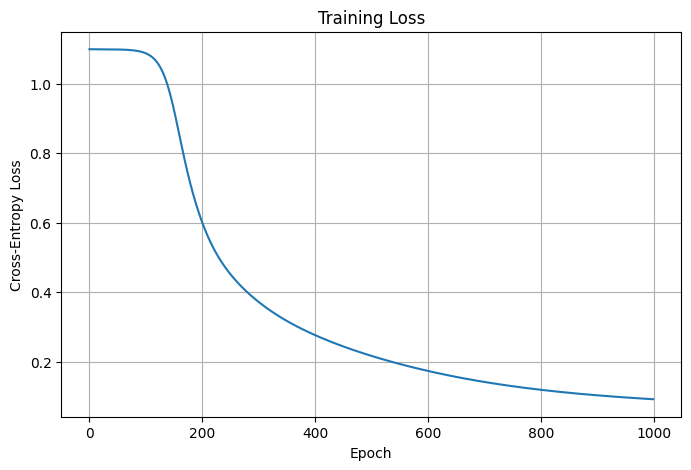

In [ ]:
# Plot training loss

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()


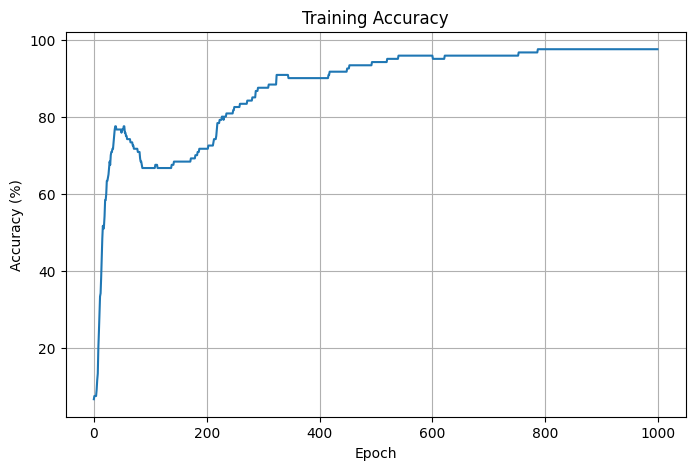

In [ ]:
# Plot training accuracy

plt.figure(figsize=(8, 5))
plt.plot(np.array(accuracy_history) * 100)
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.show()


## 12. Testing the Neural Network

After training, the model is tested on data that it did not see during training.

The test accuracy is calculated by comparing the predicted class with the actual class.


In [ ]:
# Make predictions on the test set

_, _, _, test_probabilities = forward_pass(X_test)

test_predictions = np.argmax(test_probabilities, axis=1)

test_accuracy = np.mean(test_predictions == y_test)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Test Accuracy: 96.67%


In [ ]:
# Show a few actual and predicted values

print("Actual class    Predicted class")

for actual, predicted in zip(y_test[:10], test_predictions[:10]):
    print(f"{iris.target_names[actual]:12s} {iris.target_names[predicted]:15s}")


Actual class    Predicted class
setosa       setosa         
virginica    virginica      
versicolor   versicolor     
versicolor   versicolor     
setosa       setosa         
versicolor   versicolor     
setosa       setosa         
setosa       setosa         
virginica    virginica      
versicolor   versicolor     


## 13. Sample Prediction Probabilities

The output layer gives three probabilities for every flower. The probability with the highest value is selected as the predicted class.


In [ ]:
# Display prediction probabilities for a few test samples

for i in range(5):
    print(f"Sample {i + 1}")
    print("Actual class:", iris.target_names[y_test[i]])
    print("Probabilities:", np.round(test_probabilities[i], 4))
    print("Predicted class:", iris.target_names[test_predictions[i]])
    print("-" * 50)


Sample 1
Actual class: setosa
Probabilities: [9.973e-01 2.500e-03 2.000e-04]
Predicted class: setosa
--------------------------------------------------
Sample 2
Actual class: virginica
Probabilities: [0.0057 0.2703 0.724 ]
Predicted class: virginica
--------------------------------------------------
Sample 3
Actual class: versicolor
Probabilities: [0.0703 0.903  0.0266]
Predicted class: versicolor
--------------------------------------------------
Sample 4
Actual class: versicolor
Probabilities: [0.0394 0.9354 0.0252]
Predicted class: versicolor
--------------------------------------------------
Sample 5
Actual class: setosa
Probabilities: [9.989e-01 1.100e-03 1.000e-04]
Predicted class: setosa
--------------------------------------------------


## 14. Conclusion

In this practical, I implemented a basic feedforward neural network from scratch using Python and NumPy.

The main steps I understood were:

- loading and preprocessing the dataset,
- initializing weights and biases,
- performing a forward pass,
- applying ReLU and Softmax activation functions,
- calculating cross-entropy loss,
- performing backpropagation,
- updating parameters using gradient descent,
- and evaluating the model on unseen test data.

The Iris dataset was useful for understanding the complete training process because it is small and easy to interpret.

### Result

The neural network was able to learn the classification task and achieve a good test accuracy. The exact accuracy can change slightly if the initialization, learning rate, or number of epochs is changed.


## 15. Declaration

I, **GUNJAN PRAMOD BALAPURE**, confirm that the work submitted in this assignment is my own and has been completed following academic integrity guidelines.

The code is uploaded on my GitHub repository account, and the repository link is provided below.

**GitHub Repository Link:**[Practicle_1 Click here <-](https://github.com/GunjanBalapure/Gen_AI_Lab)

**Signature:** Gunjan Pramod Balapure


## 16. Submission Checklist

- [ ] Jupyter Notebook file submitted
- [ ] Dataset source/link mentioned
- [ ] Code cells executed sequentially
- [ ] Training loss graph included
- [ ] Training accuracy graph included
- [ ] Test accuracy displayed
- [ ] Sample predictions displayed
- [ ] Screenshots of model performance taken if required
- [ ] GitHub repository link added
- [ ] Readme file added
- [ ] Student information completed
